<a href="https://colab.research.google.com/github/asrorbek0202/ML_machineLearning/blob/main/data_viz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
Matplotlib ==> Qachon ishlatiladi: Noldan maxsus yoki murakkab grafik tuzish kerak boʻlganda.
Past darajali (Low-level) — koʻproq nazorat.Koʻproq kod yozish talab etiladi.Oddiy dizayn va NumPy DataFrame bilan ishlanadi
'''
# =================================== #
'''
Seaborn ==> Matplotlib ustiga qurilgan yuqori darajali (high-level) kutubxona boʻlib, statistika va ma'lumotlar tahlili (Data Science) uchun
maxsus moʻljallangan.Kam kod bilan murakkab grafik chiziladi.zamonaviy dizayn va Pandas DataFrames bilan ishlashga moslashgan
'''

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

uylar = pd.DataFrame({
    "maydon":  [65, 90, 120, 45, 78],
    "xonalar": [2, 3, 4, 1, 3],
    "tuman":   ["Yunusobod", "Chilonzor", "Mirzo Ulug'bek", "Sergeli", "Yakkasaroy"],
    "yosh":    [12, 5, 2, 25, 8],
    "narx":    [620, 780, 1150, 380, 810],
})

print(uylar)

   maydon  xonalar           tuman  yosh  narx
0      65        2       Yunusobod    12   620
1      90        3       Chilonzor     5   780
2     120        4  Mirzo Ulug'bek     2  1150
3      45        1         Sergeli    25   380
4      78        3      Yakkasaroy     8   810


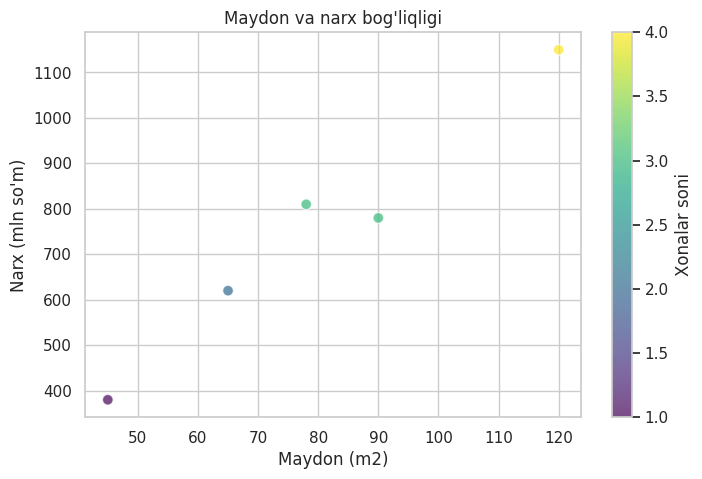

In [31]:
# Grafik turlarini korib chiqamiz
# Nuqtali diagramma
plt.figure(figsize=(8, 5))
plt.scatter(uylar["maydon"], uylar["narx"],
            c=uylar["xonalar"], cmap="viridis",
            s=60, alpha=0.7, edgecolors="white")

plt.colorbar(label="Xonalar soni")
plt.xlabel("Maydon (m2)")
plt.ylabel("Narx (mln so'm)")
plt.title("Maydon va narx bog'liqligi")
plt.show()

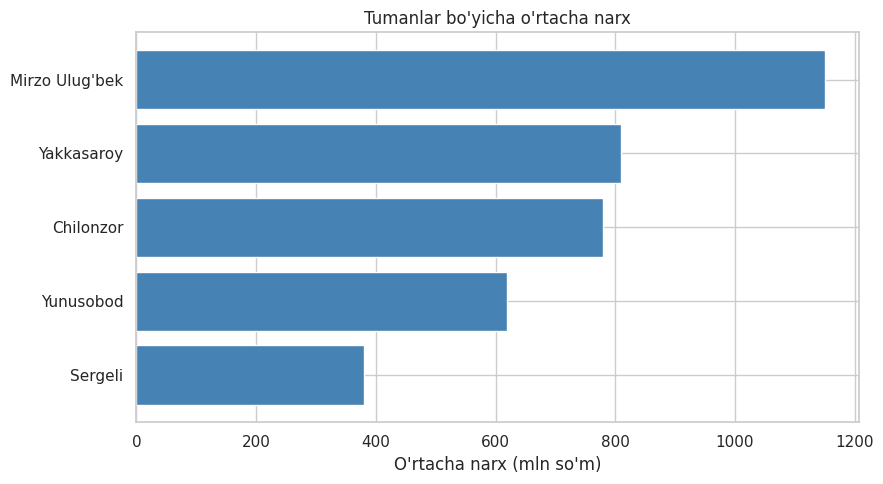

In [38]:
# Ustunli diagramma orqali tumanlardagi ortacha narx xisoblaymiz
ortacha = uylar.groupby("tuman")["narx"].mean().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(ortacha.index, ortacha.values, color="steelblue")
plt.xlabel("O'rtacha narx (mln so'm)")
plt.title("Tumanlar bo'yicha o'rtacha narx")
plt.tight_layout()
plt.show()

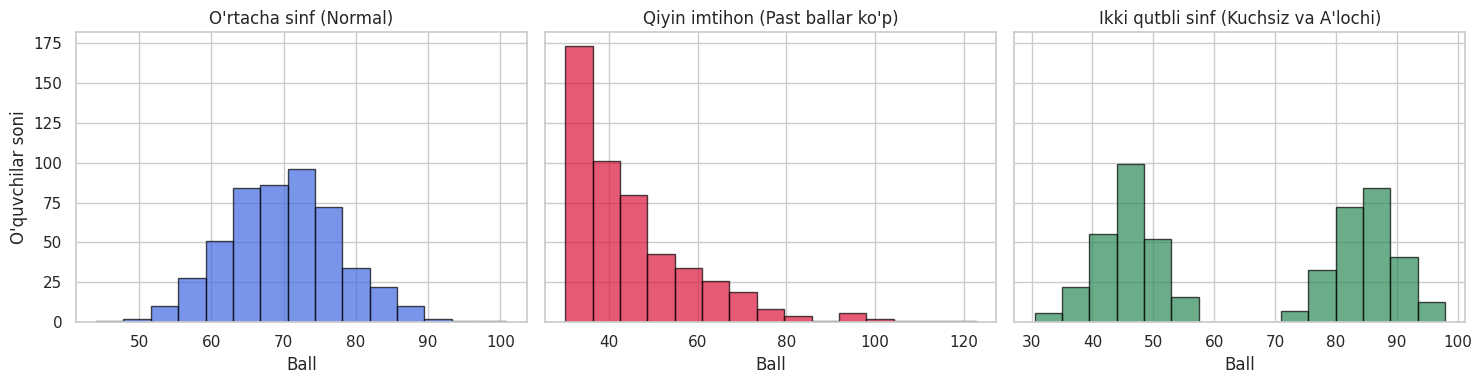

In [35]:
# ML ning eng kop ishlatiladigan gistogramma

np.random.seed(42)

normal_class = np.random.normal(loc=70, scale=8, size=500)

hard_exam = np.random.exponential(scale=15, size=500) + 30

bimodal_class = np.concatenate([
    np.random.normal(loc=45, scale=5, size=250),
    np.random.normal(loc=85, scale=5, size=250)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# 1-grafik: Normal taqsimot
axes[0].hist(normal_class, bins=15, color="royalblue", edgecolor="black", alpha=0.7)
axes[0].set_title("O'rtacha sinf (Normal)")
axes[0].set_xlabel("Ball")
axes[0].set_ylabel("O'quvchilar soni")

# 2-grafik: Qiyin imtihon
axes[1].hist(hard_exam, bins=15, color="crimson", edgecolor="black", alpha=0.7)
axes[1].set_title("Qiyin imtihon (Past ballar ko'p)")
axes[1].set_xlabel("Ball")

# 3-grafik: Ikki qutbli sinf
axes[2].hist(bimodal_class, bins=15, color="seagreen", edgecolor="black", alpha=0.7)
axes[2].set_title("Ikki qutbli sinf (Kuchsiz va A'lochi)")
axes[2].set_xlabel("Ball")

plt.tight_layout()
plt.show()

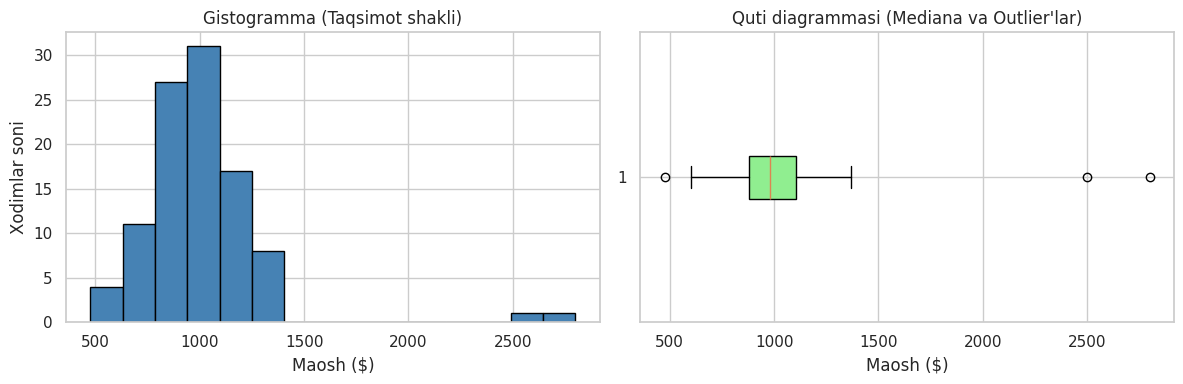

In [63]:
# Box(Quti) diagramma

np.random.seed(42)
# 100 ta xodimning maoshi (aksariyati 500-1500$, lekin 2 ta anomal juda yuqori maosh bor)
salaries = np.concatenate([np.random.normal(1000, 200, 98), [2500, 2800]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Gistogramma
axes[0].hist(salaries, bins=15, color="steelblue", edgecolor="black")
axes[0].set_title("Gistogramma (Taqsimot shakli)")
axes[0].set_xlabel("Maosh ($)")
axes[0].set_ylabel("Xodimlar soni")

# 2. Quti diagrammasi (Box Plot)
axes[1].boxplot(salaries, vert=False, patch_artist=True,
                boxprops=dict(facecolor="lightgreen"))
axes[1].set_title("Quti diagrammasi (Mediana va Outlier'lar)")
axes[1].set_xlabel("Maosh ($)")

plt.tight_layout()
plt.show()

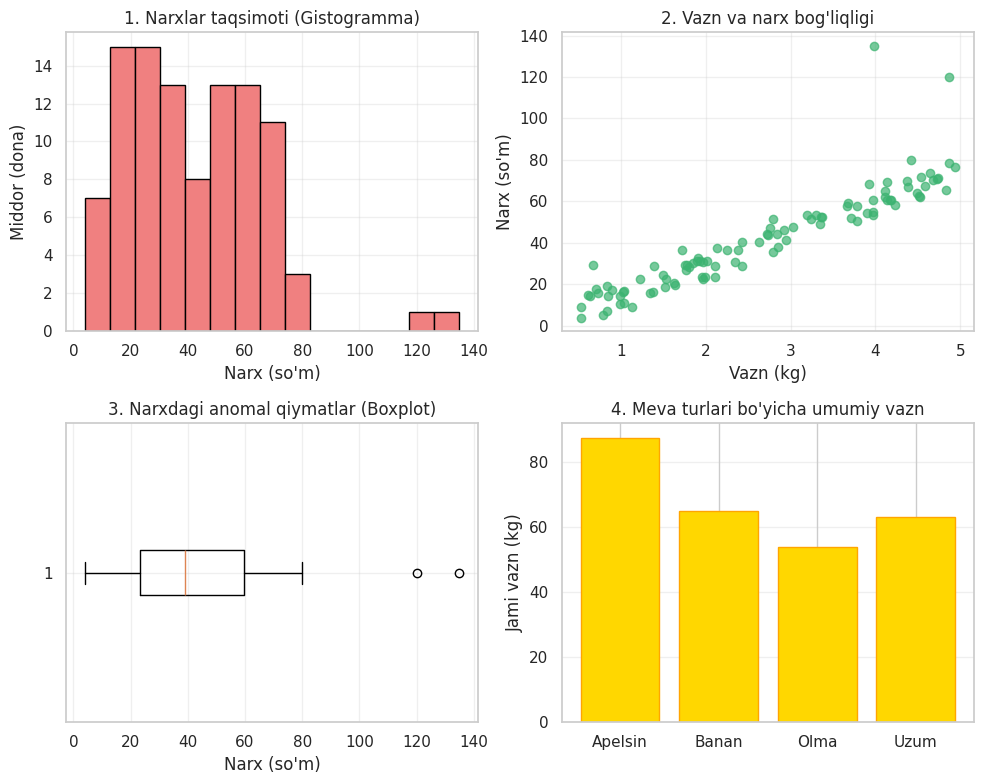

In [50]:

#Gistogramma: Ko'pchilik xaridlar qaysi oralig'ida ekanligini va qancha xarid shu oraliqqa tushganini ko'rsatadi.
# Scatter Plot: Meva vazni ortgan sari narxi ham o'sib borishini (to'g'ri mutanosiblikni) nuqtalar orqali ko'ramiz.
# Boxplot: O'ng tarafdagi alohida 120 va 135 so'mlik 2 ta nuqta — mevalar ichida anomal darajada qimmat sotilganlarini ko'rsatadi.
# Bar Chart: Olma, banan, uzum va apelsinlardan qaysi biri jami kg hisobida eng ko'p sotilganini ustunlar balandligida solishtiradi.

# 1. Mevalar bo'yicha sodda ma'lumotlar ro'yxatini shakllantiramiz. misol un narxlar bir xil
np.random.seed(42)
n = 100 # xaridlar soni

meva_turlari = ['Olma', 'Banan', 'Uzum', 'Apelsin']
sotilgan_mevalar = np.random.choice(meva_turlari, n)
vazn = np.random.uniform(0.5, 5.0, n)  # 0.5 kg dan 5 kg gacha
narx = vazn * 15 + np.random.normal(0, 5, n) # Vaznga qarab narx

# Bir nechta anomal (o'ta qimmat) narx qo'shamiz
narx[0] = 120
narx[1] = 135

# DataFrame yaratamiz
mevalar = pd.DataFrame({'meva': sotilgan_mevalar, 'vazn': vazn, 'narx': narx})
jami_sotuv = mevalar.groupby('meva')['vazn'].sum()

# 2. Oyna va 2x2 kataklarni yaratamiz
fig, oynalar = plt.subplots(2, 2, figsize=(10, 8))

# 1-grafik: Gistogramma (Narxlar taqsimoti)
oynalar[0, 0].hist(mevalar["narx"], bins=15, color="lightcoral", edgecolor="black")
oynalar[0, 0].set_title("1. Narxlar taqsimoti (Gistogramma)")
oynalar[0, 0].set_xlabel("Narx (so'm)")
oynalar[0, 0].set_ylabel("Middor (dona)")
oynalar[0, 0].grid(alpha=0.3)

# 2-grafik: Scatter Plot (Vazn va narx bog'liqligi)
oynalar[0, 1].scatter(mevalar["vazn"], mevalar["narx"], color="mediumseagreen", alpha=0.7)
oynalar[0, 1].set_title("2. Vazn va narx bog'liqligi")
oynalar[0, 1].set_xlabel("Vazn (kg)")
oynalar[0, 1].set_ylabel("Narx (so'm)")
oynalar[0, 1].grid(alpha=0.3)

# 3-grafik: Boxplot (Anomal narxlar)
oynalar[1, 0].boxplot(mevalar["narx"], vert=False)
oynalar[1, 0].set_title("3. Narxdagi anomal qiymatlar (Boxplot)")
oynalar[1, 0].set_xlabel("Narx (so'm)")
oynalar[1, 0].grid(alpha=0.3)

# 4-grafik: Bar Chart (Meva turlari bo'yicha sotuv)
oynalar[1, 1].bar(jami_sotuv.index, jami_sotuv.values, color="gold", edgecolor="orange")
oynalar[1, 1].set_title("4. Meva turlari bo'yicha umumiy vazn")
oynalar[1, 1].set_ylabel("Jami vazn (kg)")
oynalar[1, 1].grid(axis="y", alpha=0.3)


plt.tight_layout()
plt.show()

In [59]:
# Seaborn orqali tezroq va chiroyliroq
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

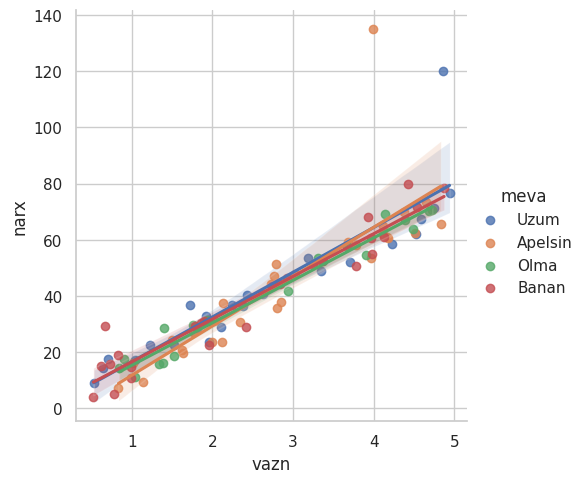

In [54]:
# 1. Nuqtali + regressiya chizig'i
sns.lmplot(data=mevalar, x="vazn", y="narx", hue="meva", height=5)



<Axes: xlabel='narx', ylabel='Count'>

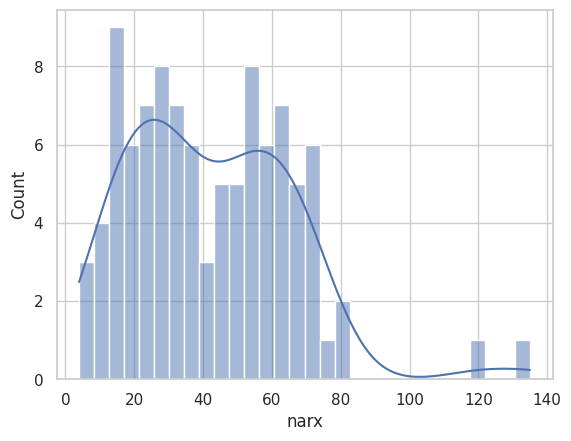

In [55]:
# 2. Taqsimot
sns.histplot(data=mevalar, x="narx", kde=True, bins=30)

<Axes: xlabel='meva', ylabel='narx'>

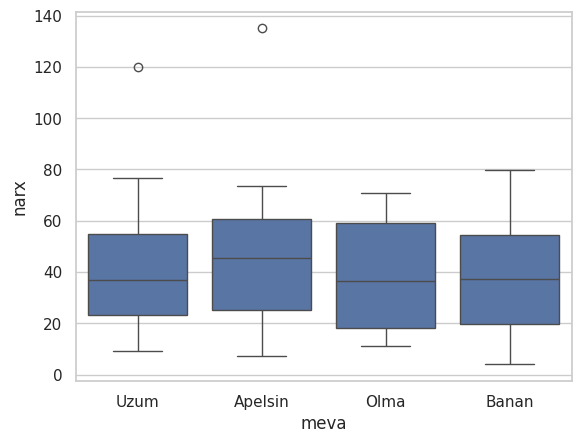

In [56]:
# 3. Quti diagramma
sns.boxplot(data=mevalar, x="meva", y="narx")

<Axes: xlabel='meva', ylabel='count'>

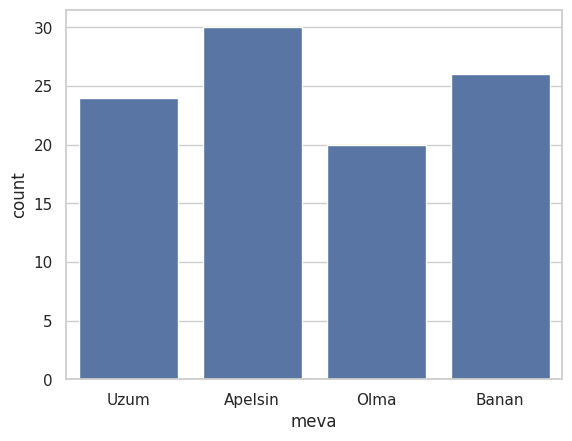

In [58]:
# 5. Sanash (Meva xaridlari soni)
sns.countplot(data=mevalar, x="meva")

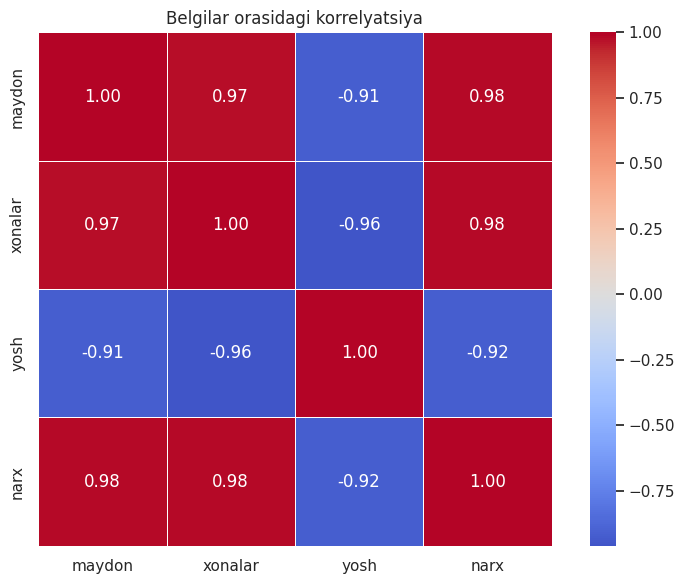

In [64]:
# (Correlation Heatmap) Machine Learning (ML) va Data Science'da eng ko'p ishlatiladigan Top-1 grafiklardan biridir.
uylar = pd.DataFrame({
    "maydon":  [65, 90, 120, 45, 78],
    "xonalar": [2, 3, 4, 1, 3],
    "tuman":   ["Yunusobod", "Chilonzor", "Mirzo Ulug'bek", "Sergeli", "Yakkasaroy"],
    "yosh":    [12, 5, 2, 25, 8],
    "narx":    [620, 780, 1150, 380, 810],
})

sonli = uylar.select_dtypes(include="number")

plt.figure(figsize=(8, 6))
sns.heatmap(
    sonli.corr(),
    annot=True,           # raqamlarni yozish
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("Belgilar orasidagi korrelyatsiya")
plt.tight_layout()
plt.show()

In [67]:
plt.savefig("tahlil.png", dpi=150, bbox_inches="tight")
plt.savefig("tahlil.svg")     # vektor - hujjat uchun

<Figure size 640x480 with 0 Axes>